# Прогнозирование доходности AAPL: ARIMA, XGBoost и ансамбль

**Исследовательский вопрос.** Улучшает ли ансамбль прогноз дневной доходности акции по сравнению с отдельными моделями и простыми ориентирами?

**Горизонт:** один следующий торговый день. **Целевая переменная:** логарифмическая доходность в процентных пунктах. **Главная метрика:** RMSE в базисных пунктах (1 б.п. = 0,01%). Исследование воспроизводится сверху вниз: расчёты выполняются в ячейках, готовые таблицы результатов не загружаются.

## 1. Источник данных и проверка качества

Исторические дневные OHLCV-котировки Apple (AAPL) получены из [Yahoo Finance](https://finance.yahoo.com/quote/AAPL/history/) через [`yfinance.download`](https://ranaroussi.github.io/yfinance/reference/api/yfinance.download.html). Параметры загрузки: `start="2014-01-01"`, `end="2025-01-01"` (конец интервала не включается), `auto_adjust=True`. Поэтому цены Open/High/Low/Close скорректированы с учётом корпоративных действий; объём торгов хранится отдельно. Копия исходных данных лежит в `data/aapl_2014_2024.csv`, чтобы расчёты не зависели от доступности Yahoo Finance при каждом запуске.

Ниже дана функция для повторной загрузки. По умолчанию она **не вызывается**: исследование использует зафиксированный CSV. При обновлении исходного файла результаты могут измениться.

In [1]:
from pathlib import Path

def refresh_data_from_yahoo():
    import yfinance as yf
    import pandas as pd

    root = Path.cwd()
    if not (root / 'data').exists():
        root = root.parent
    downloaded = yf.download(
        'AAPL', start='2014-01-01', end='2025-01-01',
        interval='1d', auto_adjust=True, progress=False, threads=False
    )
    if downloaded.empty:
        raise RuntimeError('Yahoo Finance не вернул данные')
    if isinstance(downloaded.columns, pd.MultiIndex):
        downloaded.columns = downloaded.columns.get_level_values(0)
    output = root / 'data' / 'aapl_2014_2024.csv'
    downloaded.reset_index()[
        ['Date', 'Open', 'High', 'Low', 'Close', 'Volume']
    ].to_csv(output, index=False)
    return output

# При необходимости: refresh_data_from_yahoo()

In [2]:
from pathlib import Path
import warnings

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from xgboost import XGBRegressor

SEED = 42
PROJECT = Path.cwd()
if not (PROJECT / "data" / "aapl_2014_2024.csv").exists():
    PROJECT = PROJECT.parent
DATA_FILE = PROJECT / "data" / "aapl_2014_2024.csv"
FIGURES = PROJECT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

raw = pd.read_csv(DATA_FILE, parse_dates=["Date"]).sort_values("Date")
quality = pd.Series({
    "строк": len(raw),
    "первая дата": raw["Date"].min().date(),
    "последняя дата": raw["Date"].max().date(),
    "дубликатов дат": int(raw["Date"].duplicated().sum()),
    "пропусков": int(raw.isna().sum().sum()),
    "неположительных цен Close": int((raw["Close"] <= 0).sum()),
    "неположительных объёмов": int((raw["Volume"] <= 0).sum()),
})
display(quality.to_frame("значение"))
display(raw.head(3))
assert len(raw) == 2768
assert raw["Date"].is_unique and not raw.isna().any().any()
assert (raw[["Open", "High", "Low", "Close"]] > 0).all().all()
prices = raw.set_index("Date")

,значение
строк,2768
первая дата,2014-01-02
последняя дата,2024-12-31
дубликатов дат,0
пропусков,0
неположительных цен Close,0
неположительных объёмов,0


,Date,Open,High,Low,Close,Volume
0,2014-01-02,17.189003,17.230763,17.075787,17.110123,234684800
1,2014-01-03,17.101777,17.127760,16.717275,16.734289,392467600
2,2014-01-06,16.625095,16.914320,16.506001,16.825542,412610800


## 2. Первичный анализ ряда

Цена акции растёт долгосрочно и содержит разрывы масштабов: моделировать её уровень как стационарный ряд было бы сомнительно. Перейдём к дневной лог-доходности

\[
r_t = 100\left(\ln C_t-\ln C_{t-1}\right),
\]

где \(C_t\) — скорректированная цена закрытия. Для первичного анализа показываем только тренировочный период до конца 2022 года; 2024 год пока не используем для решений по модели.

,тренировочный период
count,2265.000
mean,0.089
std,1.836
min,-13.771
1%,-5.084
5%,-2.783
50%,0.089
95%,2.810
99%,4.902
max,11.316


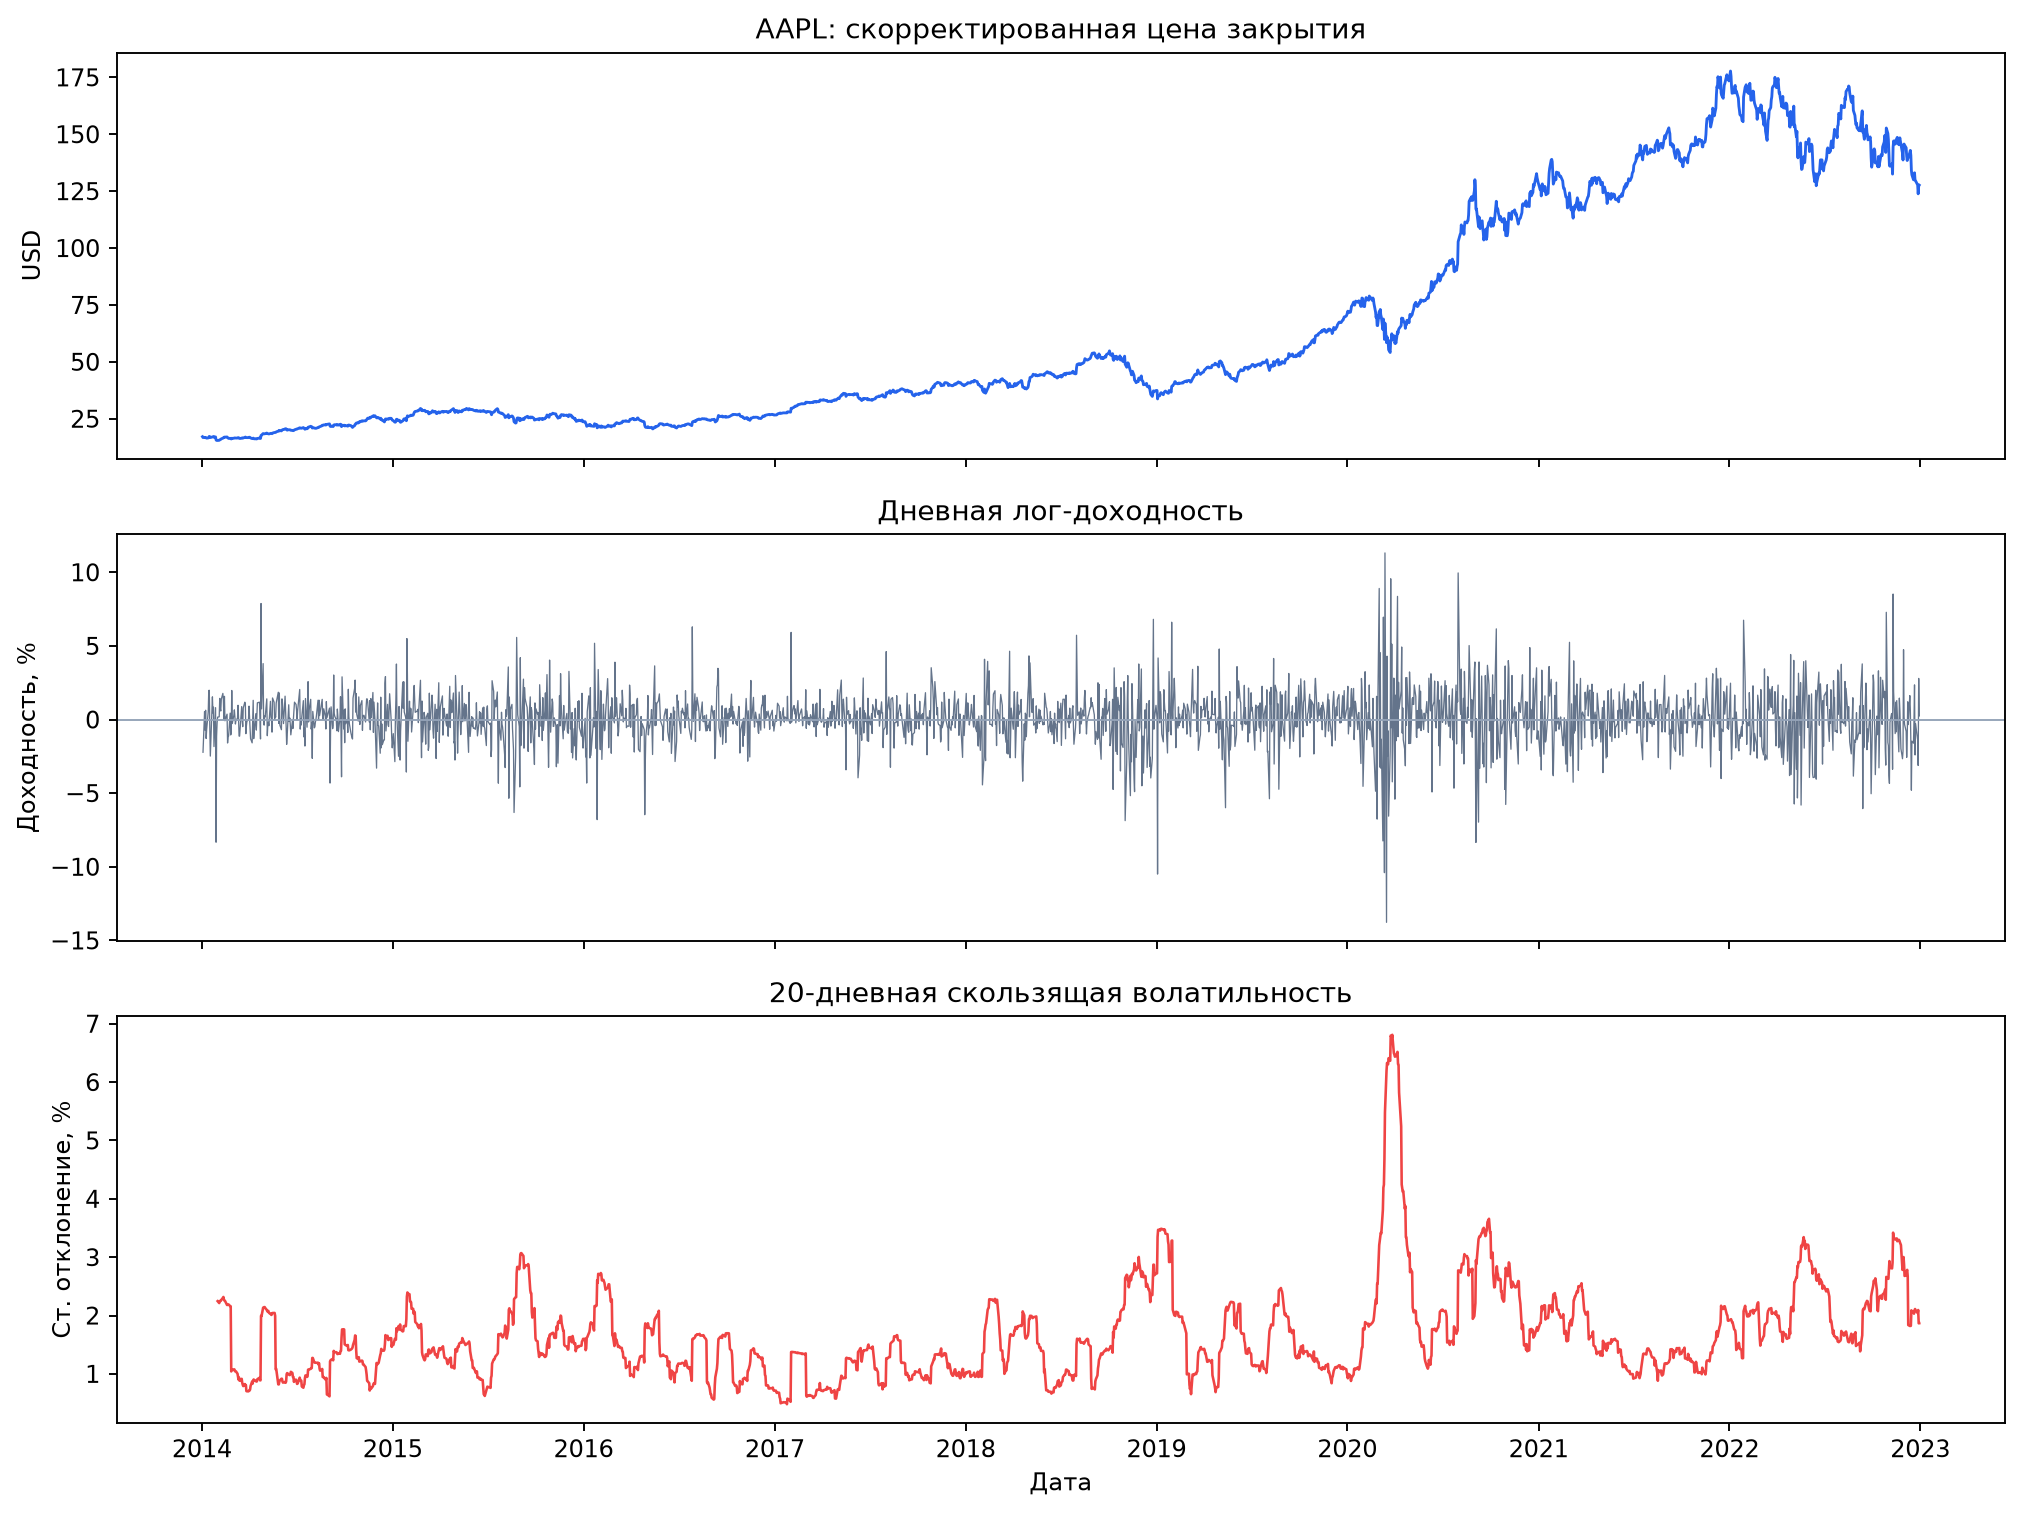

In [3]:
returns = (np.log(prices["Close"]).diff() * 100).rename("return_pct")
eda = pd.DataFrame({
    "Close": prices["Close"],
    "return_pct": returns,
}).loc[:"2022-12-31"]

summary = eda["return_pct"].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99])
summary.loc["skew"] = eda["return_pct"].skew()
summary.loc["excess_kurtosis"] = eda["return_pct"].kurt()
display(summary.round(3).to_frame("тренировочный период"))

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
axes[0].plot(eda.index, eda["Close"], color="#2563eb", lw=1.2)
axes[0].set(ylabel="USD", title="AAPL: скорректированная цена закрытия")
axes[1].plot(eda.index, eda["return_pct"], color="#64748b", lw=0.55)
axes[1].axhline(0, color="#94a3b8", lw=0.8)
axes[1].set(ylabel="Доходность, %", title="Дневная лог-доходность")
axes[2].plot(eda.index, eda["return_pct"].rolling(20).std(),
             color="#ef4444", lw=1.1)
axes[2].set(ylabel="Ст. отклонение, %", xlabel="Дата",
            title="20-дневная скользящая волатильность")
fig.tight_layout()
fig.savefig(FIGURES / "01_exploration.png", dpi=170, bbox_inches="tight")
display(Image(filename=str(FIGURES / "01_exploration.png")))
plt.close(fig)

На графике видны выбросы и меняющаяся волатильность, особенно в 2020 году. Это важно для оценки модели: маленькое снижение средней ошибки может быть нестабильным между рыночными режимами.

Проверим два свойства тренировочной доходности: ADF тест на единичный корень и Ljung–Box тест на автокорреляцию. ADF с малым p-value позволяет отвергнуть единичный корень; это не доказывает предсказуемость доходности.

In [4]:
train_returns = returns.loc[:"2022-12-31"].dropna()
adf_result = adfuller(train_returns, autolag="AIC")
ljung_box = acorr_ljungbox(train_returns, lags=[5, 10, 20], return_df=True)
diagnostics = pd.DataFrame({
    "тест": ["ADF"] + ["Ljung–Box"] * 3,
    "лаг": [np.nan, 5, 10, 20],
    "статистика": [adf_result[0]] + ljung_box["lb_stat"].tolist(),
    "p-value": [adf_result[1]] + ljung_box["lb_pvalue"].tolist(),
})
display(diagnostics.round(5))

/var/folders/3k/42v7lp8n43z_p4j3m6861sj80000gn/T/ipykernel_95423/187302451.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(train_returns, autolag="AIC")


,тест,лаг,статистика,p-value
0,ADF,NaN,-15.01011,0.00000
1,Ljung–Box,5.0,17.40989,0.00378
2,Ljung–Box,10.0,78.93811,0.00000
3,Ljung–Box,20.0,107.26737,0.00000


## 3. Признаки и защита от утечки

Для прогноза \(r_t\) доступны только данные до закрытия \(t-1\). Поэтому все рыночные признаки строятся из сдвинутых рядов. Календарный день недели \(t\) известен заранее. Первые строки с неполными скользящими окнами исключаем.

In [5]:
frame = pd.DataFrame(index=prices.index)
frame["target_return"] = returns

for lag in (1, 2, 3, 5, 10, 15, 20):
    frame[f"return_lag_{lag}"] = returns.shift(lag)

known_returns = returns.shift(1)
for window in (5, 10, 20, 60):
    frame[f"return_mean_{window}"] = known_returns.rolling(window).mean()
    frame[f"volatility_{window}"] = known_returns.rolling(window).std()

prior_close = prices["Close"].shift(1)
for window in (5, 20, 60):
    frame[f"price_vs_ma_{window}"] = (
        prior_close / prior_close.rolling(window).mean() - 1
    )

frame["intraday_range_lag_1"] = (
    (prices["High"] - prices["Low"]) / prices["Close"]
).shift(1)
frame["volume_change_lag_1"] = (
    np.log(prices["Volume"].replace(0, np.nan)).diff().shift(1)
)
frame["weekday_sin"] = np.sin(2 * np.pi * frame.index.dayofweek / 5)
frame["weekday_cos"] = np.cos(2 * np.pi * frame.index.dayofweek / 5)
frame = frame.replace([np.inf, -np.inf], np.nan).dropna()

features = frame.columns.drop("target_return").tolist()
print(f"После формирования признаков: {len(frame)} наблюдений, {len(features)} признаков")
print(f"Первое наблюдение: {frame.index.min().date()}")
display(frame.iloc[:3, :8].round(3))
assert frame.index.is_monotonic_increasing
assert not frame.isna().any().any()

После формирования признаков: 2707 наблюдений, 22 признаков
Первое наблюдение: 2014-04-01


,target_return,return_lag_1,return_lag_2,return_lag_3,return_lag_5,return_lag_10,return_lag_15,return_lag_20
Date,,,,,,,,
2014-04-01,0.911,-0.022,-0.112,-0.431,1.070,0.881,0.969,0.657
2014-04-02,0.166,0.911,-0.022,-0.112,-0.961,-0.026,0.097,0.211
2014-04-03,-0.695,0.166,0.911,-0.022,-0.431,-0.483,-1.117,-0.303


## 4. Хронологическое разбиение и простые ориентиры

**Train:** до 31.12.2022 — обучение ARIMA и временная кросс-валидация XGBoost. **Validation:** 2023 — выбор порядка ARIMA и веса ансамбля. **Test:** 2024 — финальная оценка после всех решений. Случайное перемешивание здесь недопустимо.

Сравним модели с прогнозом нулевой доходности и с историческим средним. Для направления дополнительно используем правило «всегда рост»: оно показывает, сколько можно получить только за счёт дисбаланса знаков в тестовом году.

In [6]:
train = frame.loc[:"2022-12-31"]
valid = frame.loc["2023-01-01":"2023-12-31"]
test = frame.loc["2024-01-01":"2024-12-31"]
splits = pd.DataFrame([
    {"период": name, "начало": part.index.min().date(),
     "конец": part.index.max().date(), "наблюдений": len(part)}
    for name, part in [("train", train), ("validation", valid), ("test", test)]
])
display(splits)
assert len(train) == 2205 and len(valid) == 250 and len(test) == 252
assert train.index.max() < valid.index.min() < test.index.min()

,период,начало,конец,наблюдений
0,train,2014-04-01,2022-12-30,2205
1,validation,2023-01-03,2023-12-29,250
2,test,2024-01-02,2024-12-31,252


## 5. ARIMA: выбор порядка и последовательный прогноз

Для доходности рассматриваем небольшую сетку ARIMA\((p,0,q)\), \(p,q\in\{0,1,2\}\), \(p+q\leq3\). Поскольку тест ADF отвергает единичный корень, дополнительное дифференцирование доходности не требуется.

На каждом дне валидации прогноз делается **до** добавления фактической доходности этого дня. Затем факт добавляется в историю без переоценки коэффициентов; это имитирует ежедневное использование модели. Порядок выбираем по RMSE валидации.

In [7]:
def walk_forward_arima(history, future, order):
    """One-step forecasts; today's fact enters state only after forecast."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        fitted = ARIMA(history.to_numpy(), order=order, trend="c").fit()
    values = []
    for actual in future.to_numpy():
        values.append(float(np.asarray(fitted.forecast(steps=1))[0]))
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            fitted = fitted.append(np.asarray([actual]), refit=False)
    return pd.Series(values, index=future.index)

arima_rows = []
for p in range(3):
    for q in range(3):
        if p + q > 3:
            continue
        order = (p, 0, q)
        forecast = walk_forward_arima(
            train["target_return"], valid["target_return"], order
        )
        arima_rows.append({
            "order": order,
            "validation_rmse_bps": mean_squared_error(
                valid["target_return"], forecast
            ) ** 0.5 * 100,
        })

arima_search = pd.DataFrame(arima_rows).sort_values(
    "validation_rmse_bps"
).reset_index(drop=True)
best_order = arima_search.loc[0, "order"]
arima_valid = walk_forward_arima(
    train["target_return"], valid["target_return"], best_order
)
display(arima_search.round(3))
print("Выбранный порядок:", best_order)

,order,validation_rmse_bps
0,"(0, 0, 0)",127.682
1,"(1, 0, 2)",128.516
2,"(1, 0, 1)",128.518
3,"(2, 0, 0)",128.519
4,"(0, 0, 2)",128.520
5,"(0, 0, 1)",128.524
6,"(1, 0, 0)",128.527
7,"(2, 0, 1)",128.546


Выбранный порядок: (0, 0, 0)


## 6. XGBoost: временная кросс-валидация

XGBoost получает только признаки из прошлого. На тренировочном интервале сравниваем шесть заранее заданных конфигураций через `TimeSeriesSplit`: четыре последовательных фолда по 126 дней, разрыв в один день. Используем неглубокие деревья и регуляризацию, чтобы сдерживать подгонку к шумной дневной доходности. После выбора конфигурации обучаем модель на всём train и получаем прогноз на validation.

In [8]:
candidate_specs = [
    (200, 2, 0.02, 10),
    (400, 2, 0.02, 10),
    (200, 3, 0.02, 10),
    (400, 3, 0.02, 20),
    (200, 2, 0.05, 20),
    (400, 2, 0.01, 20),
]
candidates = [
    dict(n_estimators=n, max_depth=depth, learning_rate=rate,
         min_child_weight=child, subsample=0.8, colsample_bytree=0.8,
         reg_lambda=10.0, reg_alpha=0.1)
    for n, depth, rate, child in candidate_specs
]

def new_xgb(params):
    return XGBRegressor(
        objective="reg:squarederror", tree_method="hist",
        random_state=SEED, n_jobs=4, **params
    )

cv = TimeSeriesSplit(n_splits=4, test_size=126, gap=1)
xgb_rows = []
for number, params in enumerate(candidates, start=1):
    fold_errors = []
    for fit_idx, score_idx in cv.split(train):
        model = new_xgb(params)
        model.fit(train.iloc[fit_idx][features],
                  train.iloc[fit_idx]["target_return"])
        forecast = model.predict(train.iloc[score_idx][features])
        fold_errors.append(mean_squared_error(
            train.iloc[score_idx]["target_return"], forecast
        ) ** 0.5 * 100)
    xgb_rows.append({
        "candidate": number, "cv_rmse_bps": np.mean(fold_errors),
        "cv_std_bps": np.std(fold_errors), **params
    })

xgb_search = pd.DataFrame(xgb_rows).sort_values(
    "cv_rmse_bps"
).reset_index(drop=True)
best_params = candidates[int(xgb_search.loc[0, "candidate"]) - 1]
xgb_valid_model = new_xgb(best_params)
xgb_valid_model.fit(train[features], train["target_return"])
xgb_valid = pd.Series(
    xgb_valid_model.predict(valid[features]), index=valid.index
)
display(xgb_search[[
    "candidate", "cv_rmse_bps", "cv_std_bps",
    "n_estimators", "max_depth", "learning_rate", "min_child_weight"
]].round(3))
print("Выбранные параметры:", best_params)

,candidate,cv_rmse_bps,cv_std_bps,n_estimators,max_depth,learning_rate,min_child_weight
0,1,190.844,35.635,200,2,0.02,10
1,6,191.471,36.381,400,2,0.01,20
2,2,191.760,36.157,400,2,0.02,10
3,3,192.397,35.784,200,3,0.02,10
4,5,192.627,36.524,200,2,0.05,20
5,4,194.115,36.669,400,3,0.02,20


Выбранные параметры: {'n_estimators': 200, 'max_depth': 2, 'learning_rate': 0.02, 'min_child_weight': 10, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_lambda': 10.0, 'reg_alpha': 0.1}


## 7. Ансамбль: вес выбирается только на 2023 году

Формула стэкинга: \(\hat r_t=w\hat r_t^{ARIMA}+(1-w)\hat r_t^{XGB}\). Оптимизируем RMSE на validation и заранее ограничиваем \(w\in[0,2]\). Это допускает отрицательный коэффициент XGBoost: он может работать как поправка к ARIMA. Выбор на 2024 году не производится.

,модель,"RMSE, б.п."
0,ARIMA,127.682
1,XGBoost,128.406
2,Ансамбль,127.544


Вес ARIMA: 1.666; вес XGBoost: -0.666


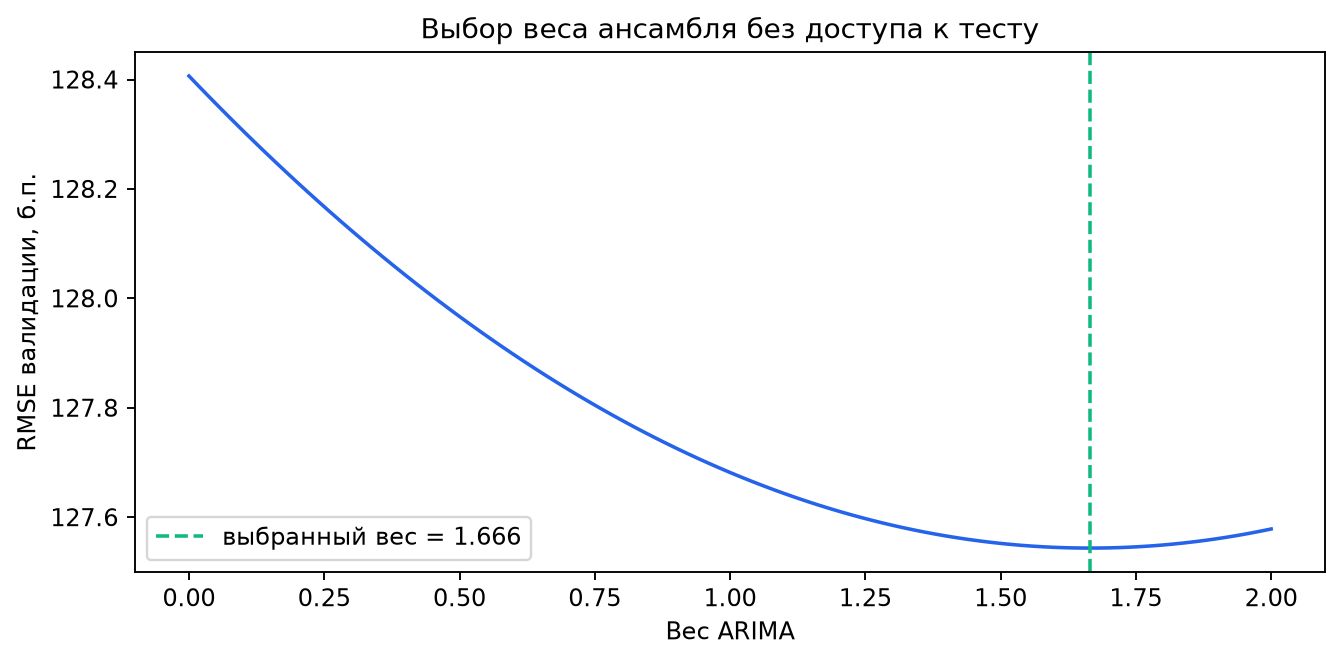

In [9]:
target_valid = valid["target_return"].to_numpy()
difference = arima_valid.to_numpy() - xgb_valid.to_numpy()
denominator = np.dot(difference, difference)
weight_arima = float(np.clip(
    np.dot(target_valid - xgb_valid.to_numpy(), difference) / denominator,
    0.0, 2.0
)) if denominator > 0 else 0.5
weight_xgb = 1.0 - weight_arima
ensemble_valid = weight_arima * arima_valid + weight_xgb * xgb_valid
validation_scores = pd.DataFrame({
    "модель": ["ARIMA", "XGBoost", "Ансамбль"],
    "RMSE, б.п.": [
        mean_squared_error(valid["target_return"], pred) ** 0.5 * 100
        for pred in [arima_valid, xgb_valid, ensemble_valid]
    ],
})
display(validation_scores.round(3))
print(f"Вес ARIMA: {weight_arima:.3f}; вес XGBoost: {weight_xgb:.3f}")

weights = np.linspace(0, 2, 101)
curve = [
    mean_squared_error(
        valid["target_return"],
        w * arima_valid + (1 - w) * xgb_valid
    ) ** 0.5 * 100
    for w in weights
]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(weights, curve, color="#2563eb")
ax.axvline(weight_arima, color="#10b981", ls="--",
           label=f"выбранный вес = {weight_arima:.3f}")
ax.set(xlabel="Вес ARIMA", ylabel="RMSE валидации, б.п.",
       title="Выбор веса ансамбля без доступа к тесту")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "02_validation_weight.png", dpi=170, bbox_inches="tight")
display(Image(filename=str(FIGURES / "02_validation_weight.png")))
plt.close(fig)

## 8. Финальный тест на 2024 году

После фиксации гиперпараметров и веса переобучаем обе модели на объединённом train + validation. ARIMA обновляет состояние после каждого уже известного факта 2024 года; XGBoost остаётся фиксированным. Так каждый прогноз на день \(t\) использует только информацию, доступную к концу \(t-1\).

In [10]:
development = pd.concat([train, valid])
arima_test = walk_forward_arima(
    development["target_return"], test["target_return"], best_order
)
xgb_model = new_xgb(best_params)
xgb_model.fit(development[features], development["target_return"])
xgb_test = pd.Series(
    xgb_model.predict(test[features]), index=test.index
)

def expanding_mean_forecast(history, future):
    total, count = float(history.sum()), len(history)
    predictions = []
    for actual in future.to_numpy():
        predictions.append(total / count)
        total += float(actual)
        count += 1
    return pd.Series(predictions, index=future.index)

predictions = pd.DataFrame({
    "Факт": test["target_return"],
    "Нулевая доходность": 0.0,
    "Историческое среднее": expanding_mean_forecast(
        development["target_return"], test["target_return"]
    ),
    "ARIMA": arima_test,
    "XGBoost": xgb_test,
})
predictions["Ансамбль"] = (
    weight_arima * predictions["ARIMA"]
    + weight_xgb * predictions["XGBoost"]
)

rows = []
for name in predictions.columns.drop("Факт"):
    forecast = predictions[name]
    rows.append({
        "модель": name,
        "RMSE, б.п.": mean_squared_error(predictions["Факт"], forecast) ** 0.5 * 100,
        "MAE, б.п.": mean_absolute_error(predictions["Факт"], forecast) * 100,
        "верное направление, %": (
            np.mean(np.sign(predictions["Факт"]) == np.sign(forecast)) * 100
            if name != "Нулевая доходность" else np.nan
        ),
    })
metrics = pd.DataFrame(rows).set_index("модель").sort_values("RMSE, б.п.")
always_up_accuracy = (predictions["Факт"] > 0).mean() * 100
display(metrics.round(3))
print(f"Простое правило «всегда рост»: {always_up_accuracy:.3f}% верных направлений")
print("Нулевому прогнозу точность знака не приписывается: он не выбирает направление.")

,"RMSE, б.п.","MAE, б.п.","верное направление, %"
модель,,,
Ансамбль,142.000,103.398,56.746
ARIMA,142.056,103.425,56.349
Историческое среднее,142.083,103.438,56.349
Нулевая доходность,142.451,104.270,NaN
XGBoost,142.483,103.562,55.556


Простое правило «всегда рост»: 56.349% верных направлений
Нулевому прогнозу точность знака не приписывается: он не выбирает направление.


Теперь покажем итоговые ошибки и пример ежедневных прогнозов. Масштаб оси RMSE на первом графике намеренно приближен, чтобы видеть различия меньше 1 б.п.; численные значения подписаны рядом с точками.

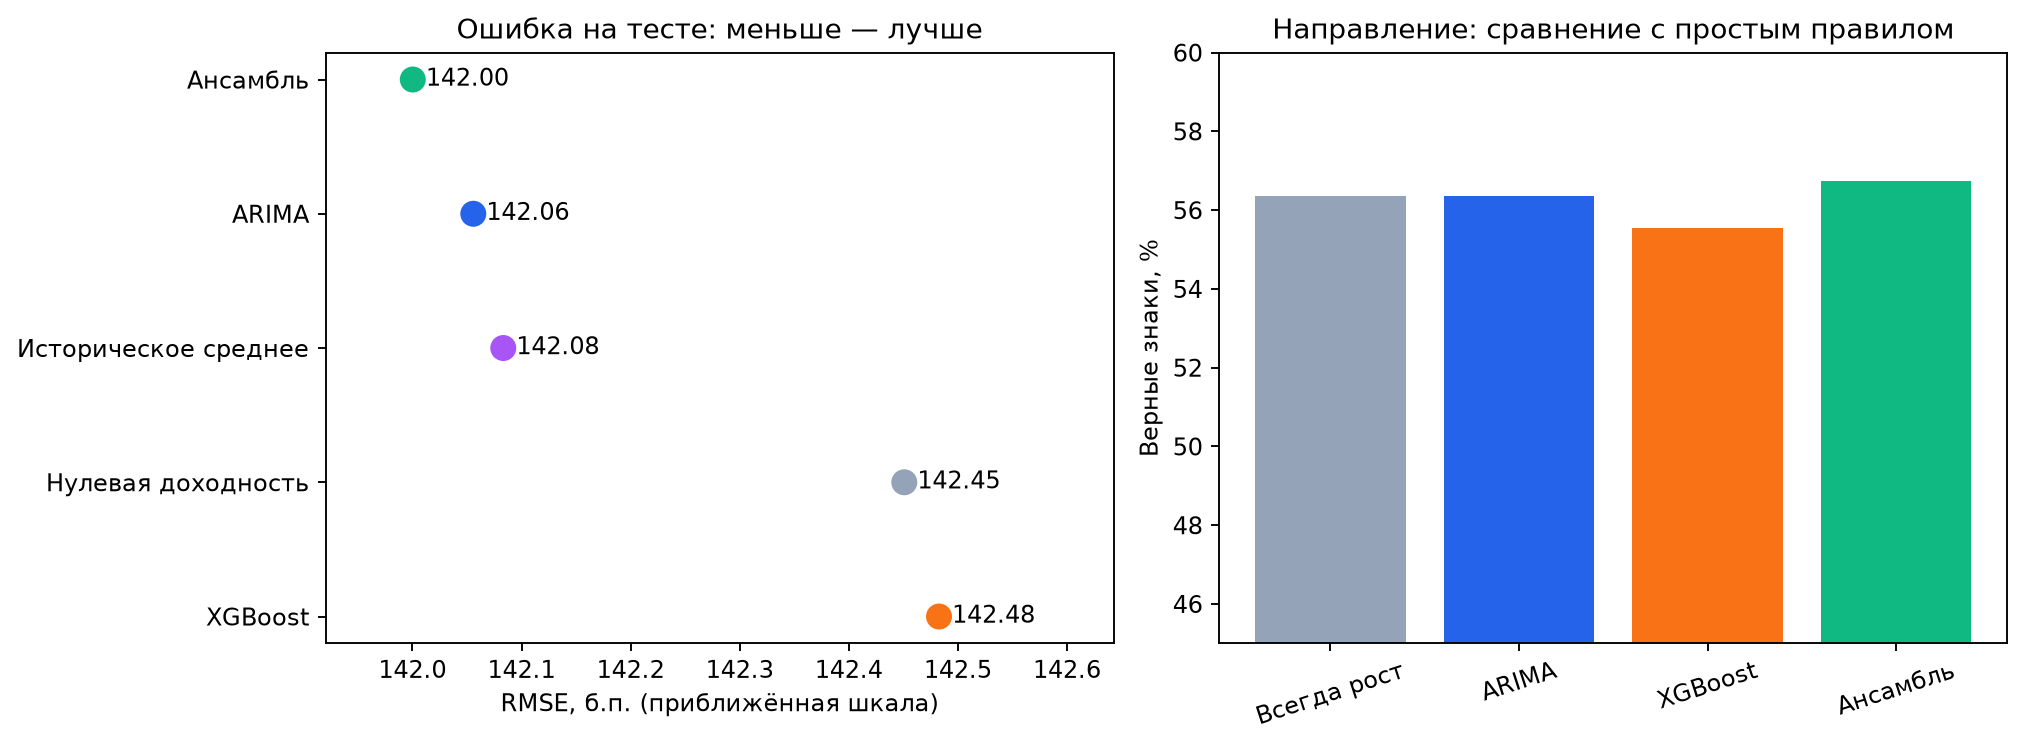

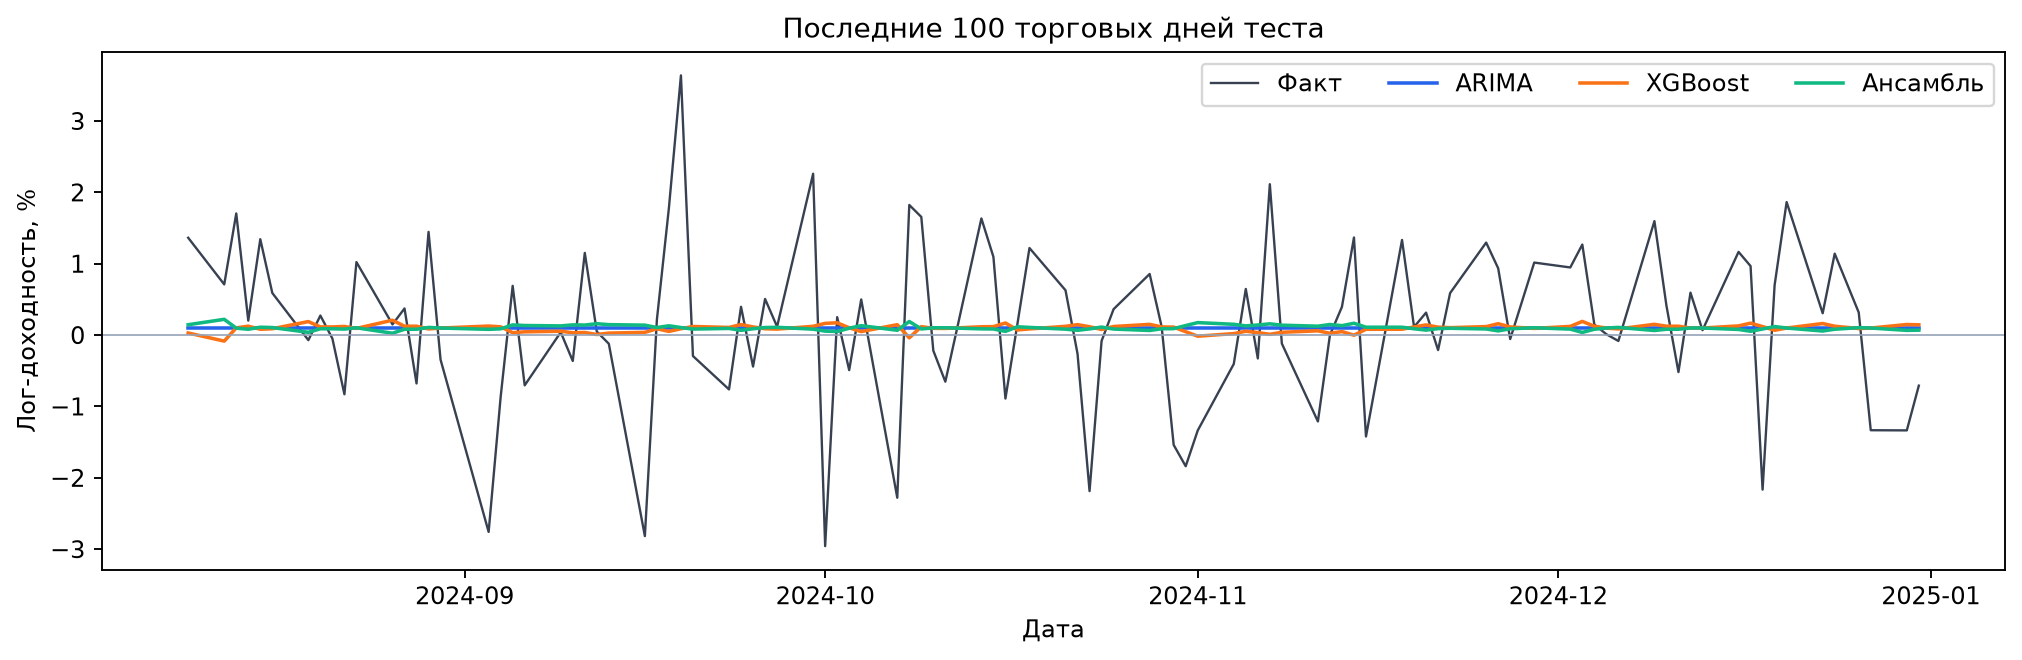

In [11]:
palette = {
    "Ансамбль": "#10b981", "ARIMA": "#2563eb",
    "XGBoost": "#f97316", "Историческое среднее": "#a855f7",
    "Нулевая доходность": "#94a3b8",
}
ordered = metrics.sort_values("RMSE, б.п.", ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
positions = np.arange(len(ordered))
axes[0].scatter(ordered["RMSE, б.п."], positions,
                color=[palette[n] for n in ordered.index], s=100)
axes[0].set_yticks(positions, labels=ordered.index)
axes[0].set_xlim(ordered["RMSE, б.п."].min() - 0.08,
                 ordered["RMSE, б.п."].max() + 0.16)
axes[0].set(xlabel="RMSE, б.п. (приближённая шкала)",
            title="Ошибка на тесте: меньше — лучше")
for y, value in enumerate(ordered["RMSE, б.п."]):
    axes[0].text(value + 0.012, y, f"{value:.2f}", va="center")
direction = metrics.loc[
    ["ARIMA", "XGBoost", "Ансамбль"], "верное направление, %"
]
axes[1].bar(["Всегда рост"] + direction.index.tolist(),
            [always_up_accuracy] + direction.tolist(),
            color=["#94a3b8"] + [palette[n] for n in direction.index])
axes[1].set_ylim(45, 60)
axes[1].set(ylabel="Верные знаки, %", title="Направление: сравнение с простым правилом")
axes[1].tick_params(axis="x", rotation=18)
fig.tight_layout()
fig.savefig(FIGURES / "03_model_comparison.png", dpi=170, bbox_inches="tight")
display(Image(filename=str(FIGURES / "03_model_comparison.png")))
plt.close(fig)

recent = predictions.tail(100)
fig, ax = plt.subplots(figsize=(12, 4))
for name in ["Факт", "ARIMA", "XGBoost", "Ансамбль"]:
    ax.plot(recent.index, recent[name], label=name,
            lw=1.0 if name == "Факт" else 1.5,
            color="#374151" if name == "Факт" else palette[name])
ax.axhline(0, color="#94a3b8", lw=0.7)
ax.set(title="Последние 100 торговых дней теста",
       ylabel="Лог-доходность, %", xlabel="Дата")
ax.legend(ncol=4)
fig.tight_layout()
fig.savefig(FIGURES / "04_forecasts.png", dpi=170, bbox_inches="tight")
display(Image(filename=str(FIGURES / "04_forecasts.png")))
plt.close(fig)

## 9. Насколько надёжен выигрыш?

Для разности RMSE используем **парный moving-block bootstrap**: в каждом повторе одинаковые 10-дневные блоки дат выбираются для ошибок обеих моделей. Это сохраняет локальную зависимость лучше независимого сэмплирования дней. Интервал относится к конкретному тестовому году и не заменяет проверку на других акциях и рыночных режимах.

In [12]:
def block_bootstrap_gain(table, comparator, block=10, repeats=2000):
    rng = np.random.default_rng(SEED)
    actual = table["Факт"].to_numpy()
    error_other = actual - table[comparator].to_numpy()
    error_ensemble = actual - table["Ансамбль"].to_numpy()
    n = len(actual)
    starts = np.arange(n - block + 1)
    gains = np.empty(repeats)
    for i in range(repeats):
        sample = []
        while len(sample) < n:
            start = int(rng.choice(starts))
            sample.extend(range(start, start + block))
        idx = np.asarray(sample[:n])
        gains[i] = (
            np.sqrt(np.mean(error_other[idx] ** 2))
            - np.sqrt(np.mean(error_ensemble[idx] ** 2))
        ) * 100
    point_gain = (
        np.sqrt(np.mean(error_other ** 2))
        - np.sqrt(np.mean(error_ensemble ** 2))
    ) * 100
    low, high = np.quantile(gains, [0.025, 0.975])
    return {
        "сравнение": f"{comparator} − Ансамбль",
        "выигрыш RMSE, б.п.": point_gain,
        "95% CI: низ": low,
        "95% CI: верх": high,
    }

uncertainty = pd.DataFrame([
    block_bootstrap_gain(predictions, "ARIMA"),
    block_bootstrap_gain(predictions, "XGBoost"),
])
display(uncertainty.round(3))

,сравнение,"выигрыш RMSE, б.п.",95% CI: низ,95% CI: верх
0,ARIMA − Ансамбль,0.055,-0.412,0.624
1,XGBoost − Ансамбль,0.482,-0.640,1.919


## 10. Какие признаки использовал XGBoost?

Показываем нормализованную важность по gain для модели, обученной на train + validation. Эта мера описывает использование признаков деревьями, но **не доказывает причинного влияния** на доходность.

,признак,нормализованный gain
16,price_vs_ma_20,0.0640
8,volatility_5,0.0630
10,volatility_10,0.0583
11,return_mean_20,0.0580
5,return_lag_15,0.0565
15,price_vs_ma_5,0.0501
18,intraday_range_lag_1,0.0483
9,return_mean_10,0.0482
13,return_mean_60,0.0464
17,price_vs_ma_60,0.0461


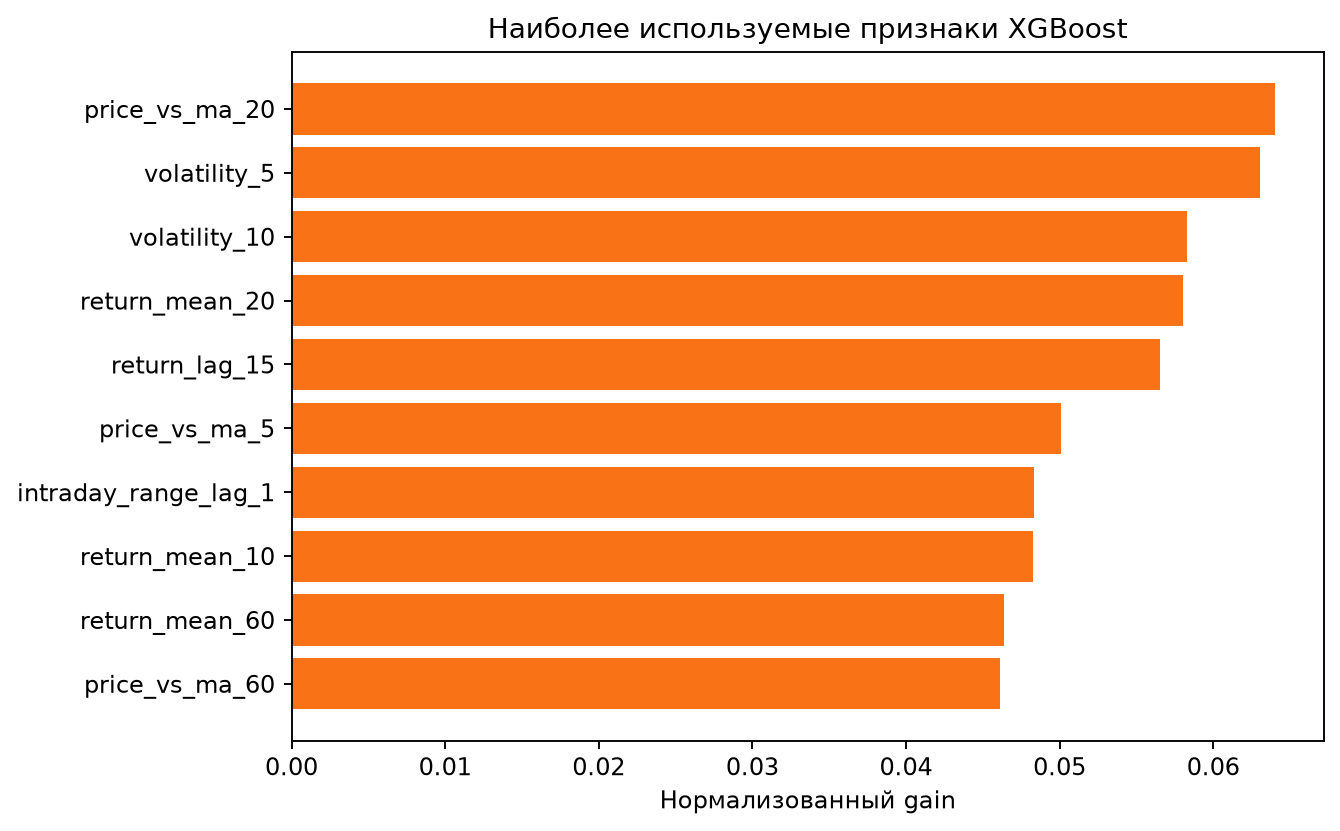

In [13]:
importance = pd.DataFrame({
    "признак": features,
    "нормализованный gain": xgb_model.feature_importances_,
}).sort_values("нормализованный gain", ascending=False)
display(importance.head(10).round(4))

top = importance.head(10).sort_values("нормализованный gain")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top["признак"], top["нормализованный gain"], color="#f97316")
ax.set(xlabel="Нормализованный gain",
       title="Наиболее используемые признаки XGBoost")
fig.tight_layout()
fig.savefig(FIGURES / "05_feature_importance.png", dpi=170, bbox_inches="tight")
display(Image(filename=str(FIGURES / "05_feature_importance.png")))
plt.close(fig)

### Сохранение результатов

Таблицы и графики в папке `reports/` формируются вычислениями этого ноутбука. Их можно использовать отдельно от ноутбука для просмотра и проверки.

In [14]:
import json

REPORTS = PROJECT / 'reports'
metrics.to_csv(REPORTS / 'metrics.csv')
predictions.to_csv(REPORTS / 'predictions.csv', index_label='Date')
splits.to_csv(REPORTS / 'data_splits.csv', index=False)
diagnostics.to_csv(REPORTS / 'statistical_diagnostics.csv', index=False)
arima_search.to_csv(REPORTS / 'arima_selection.csv', index=False)
xgb_search.to_csv(REPORTS / 'xgb_selection.csv', index=False)
validation_scores.to_csv(REPORTS / 'validation_scores.csv', index=False)
uncertainty.to_csv(REPORTS / 'bootstrap_uncertainty.csv', index=False)
importance.to_csv(REPORTS / 'feature_importance.csv', index=False)
with (REPORTS / 'model_config.json').open('w', encoding='utf-8') as file:
    json.dump({
        'arima_order': best_order,
        'xgb_params': best_params,
        'ensemble_arima_weight': weight_arima,
        'ensemble_xgb_weight': weight_xgb,
        'random_state': SEED,
    }, file, ensure_ascii=False, indent=2)
print(f'Сохранено {len(list(REPORTS.glob("*.csv")))} таблиц CSV и 5 графиков.')

Сохранено 9 таблиц CSV и 5 графиков.


## 11. Вывод и границы результата

На единственном заранее выделенном тесте 2024 года ансамбль получил **RMSE ≈ 142,00 б.п.** против **142,06 б.п.** у ARIMA и **142,48 б.п.** у XGBoost. Выбранная ARIMA\((0,0,0)\) фактически даёт постоянный прогноз: для дневной доходности более сложная авторегрессия не улучшила валидацию. Вес ансамбля около **1,666 / −0,666** был найден на 2023 году.

Выигрыш относительно ARIMA составляет лишь **≈ 0,06 б.п.**; 95% bootstrap-интервал включает ноль. Точность направления **56,7%** тоже почти совпадает с правилом «всегда рост» (**56,3%**). Следовательно, проект показывает корректный процесс сравнения и небольшой выигрыш на одном holdout, но **не подтверждает устойчивую торговую стратегию или экономически значимую альфу**.

Следующее исследование: повторить схему на нескольких акциях и последовательных временных окнах, затем оценить результаты с торговыми издержками и интервалами неопределённости. Тест 2024 года после просмотра результатов не используется для перенастройки моделей.